# Detecção de Fraude em Cartão de Crédito

Projeto de classificação com dados reais de transações de cartão de crédito, em que **só cerca de 0,17% das transações são fraude**.

Neste cenário, a **acurácia engana**: um modelo que responde "não é fraude" para tudo acerta mais de 99,8% das vezes e não detecta nenhuma fraude. Por isso, a avaliação é feita com **recall, precisão e F1 da classe fraude**, além da área sob a curva de precisão e recall (PR-AUC).

**Roteiro**
1. Exploração
2. Preparação dos dados
3. Modelos (baseline e comparação)
4. Balanceamento: peso das classes × undersampling × oversampling (SMOTE)
5. Ajuste de hiperparâmetros (`GridSearchCV`)
6. Ajuste do limiar de decisão
7. Avaliação final no teste
8. Explicabilidade (importância das variáveis e SHAP)
9. Conclusões

In [1]:
# Se estiver no Google Colab, descomente a linha abaixo:
# !pip install -q xgboost shap imbalanced-learn

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("imagens", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Exploração

O dataset é carregado **direto pelo link**, sem ficar salvo no repositório.

> Se o link da Aula 1 for diferente, basta trocar a variável `URL`. A base é a mesma (*Credit Card Fraud Detection*, ULB / Kaggle).

In [2]:
URL = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"

inicio = time.time()
df = pd.read_csv(URL)
print(f"Base carregada em {time.time() - inicio:.0f}s | {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head()

Base carregada em 6s | 284,807 linhas × 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
df[["Time", "Amount", "Class"]].describe()

Valores ausentes: 0


Linhas duplicadas: 1081


,Time,Amount,Class
count,284807.0000,284807.0000,284807.0000
mean,94813.8596,88.3496,0.0017
std,47488.1460,250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,54201.5000,5.6000,0.0000
50%,84692.0000,22.0000,0.0000
75%,139320.5000,77.1650,0.0000
max,172792.0000,25691.1600,1.0000


In [5]:
contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True) * 100
resumo = pd.DataFrame({"transações": contagem, "%": proporcao}).rename(index={0: "Normal (0)", 1: "Fraude (1)"})
resumo

,transações,%
Class,,
Normal (0),284315,99.8273
Fraude (1),492,0.1727


### Por que a acurácia engana

Vamos medir a acurácia de um "modelo" que responde **sempre "não é fraude"**:

In [6]:
acuracia_burra = (df["Class"] == 0).mean()
print(f"Acurácia prevendo sempre 'não fraude': {acuracia_burra:.4%}")
print("Fraudes detectadas por esse modelo: 0 (recall da fraude = 0%)")

Acurácia prevendo sempre 'não fraude': 99.8273%
Fraudes detectadas por esse modelo: 0 (recall da fraude = 0%)


Mais de 99,8% de acurácia e nenhuma fraude detectada. Por isso a métrica principal deste projeto é o **recall da fraude** (quantas fraudes reais o modelo pega), equilibrado com a **precisão** (quantos alertas são fraude de verdade) e o **F1**.

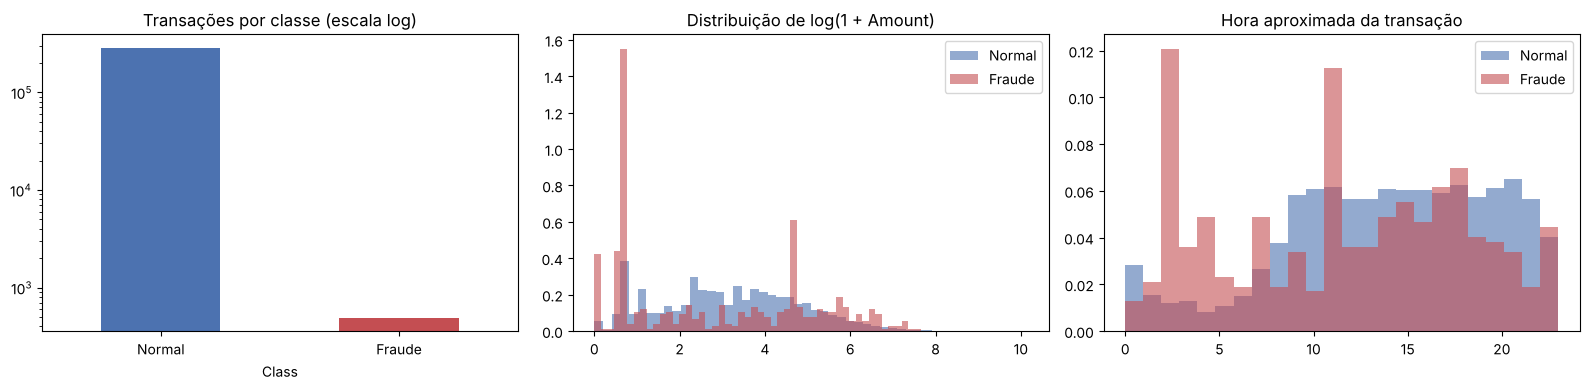

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

contagem.rename({0: "Normal", 1: "Fraude"}).plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0)
axes[0].set_yscale("log"); axes[0].set_title("Transações por classe (escala log)")

for c, cor, nome in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraude")]:
    axes[1].hist(np.log1p(df.loc[df["Class"] == c, "Amount"]), bins=50, alpha=0.6,
                 density=True, color=cor, label=nome)
axes[1].set_title("Distribuição de log(1 + Amount)"); axes[1].legend()

for c, cor, nome in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraude")]:
    axes[2].hist((df.loc[df["Class"] == c, "Time"] // 3600) % 24, bins=24, alpha=0.6,
                 density=True, color=cor, label=nome)
axes[2].set_title("Hora aproximada da transação"); axes[2].legend()

plt.tight_layout(); plt.savefig("imagens/exploracao.png", dpi=110); plt.show()

In [8]:
print("Valor das transações por classe:")
df.groupby("Class")["Amount"].describe().rename(index={0: "Normal", 1: "Fraude"})

Valor das transações por classe:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normal,284315.0000,88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,25691.1600
Fraude,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,2125.8700


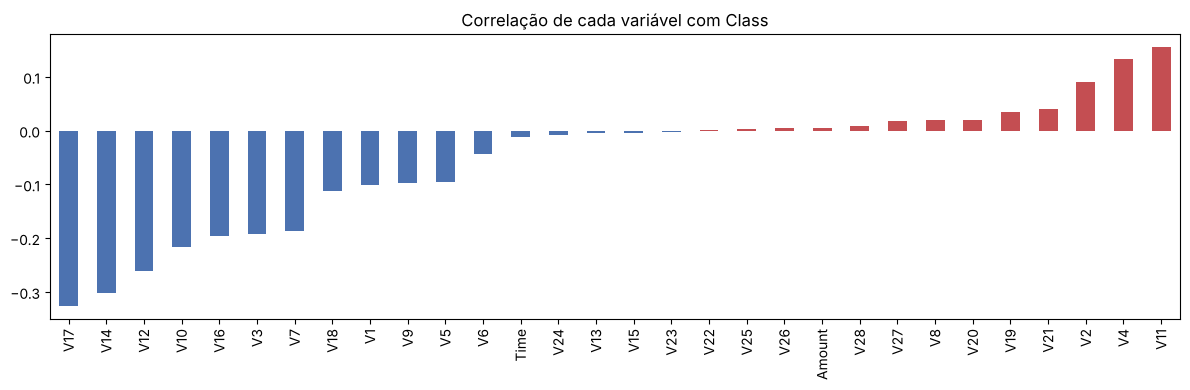

In [9]:
# Correlação de cada variável com a classe (ajuda a ter uma primeira noção do que separa fraude)
corr = df.corr()["Class"].drop("Class").sort_values()
plt.figure(figsize=(12, 4))
corr.plot.bar(color=np.where(corr > 0, "#C44E52", "#4C72B0"))
plt.title("Correlação de cada variável com Class"); plt.tight_layout()
plt.savefig("imagens/correlacao.png", dpi=110); plt.show()

**Observações da exploração**
- A base não tem valores ausentes; há algumas linhas duplicadas, que são removidas na preparação.
- `V1`–`V28` já vêm transformadas por PCA (centralizadas), mas `Time` e `Amount` estão em escalas bem diferentes.
- `Amount` é muito assimétrico (poucas transações de valor muito alto), por isso o uso do **log**.
- Variáveis como `V14`, `V17`, `V12` e `V10` têm a correlação (negativa) mais forte com fraude.

## 2. Preparação dos dados

- Remoção de duplicatas.
- **Novas variáveis:** `log_amount = log(1 + Amount)` e `hora` (hora aproximada do dia, a partir de `Time` em segundos).
- Divisão **estratificada** em treino (60%), validação (20%) e teste (20%), mantendo a proporção de fraudes nos três.
  - A **validação** é usada para escolher o limiar de decisão; o **teste** só é usado no final, para não "olhar a prova antes".
- **`StandardScaler` ajustado somente no treino**, para evitar vazamento de informação.

In [10]:
df = df.drop_duplicates().reset_index(drop=True)

df["log_amount"] = np.log1p(df["Amount"])
df["hora"] = (df["Time"] // 3600) % 24

X = df.drop(columns=["Class", "Amount", "Time"])
y = df["Class"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_val_s   = pd.DataFrame(scaler.transform(X_val),   columns=X.columns, index=X_val.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

pd.DataFrame({
    "linhas": [len(y_train), len(y_val), len(y_test)],
    "fraudes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "% fraude": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["treino", "validação", "teste"])

,linhas,fraudes,% fraude
treino,170235,284,0.1668
validação,56745,94,0.1657
teste,56746,95,0.1674


A proporção de fraudes ficou praticamente igual nos três conjuntos, graças ao `stratify`.

## 3. Modelos

Funções auxiliares para avaliar sempre do mesmo jeito, **olhando a classe fraude**:

In [11]:
def metricas(nome, y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "modelo": nome,
        "limiar": limiar,
        "recall": recall_score(y_true, pred),
        "precisão": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred),
        "PR-AUC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "fraudes detectadas": f"{int(((pred == 1) & (y_true == 1)).sum())}/{int(y_true.sum())}",
        "alarmes falsos": int(((pred == 1) & (y_true == 0)).sum()),
    }

def treinar(nome, modelo, resultados, probas):
    inicio = time.time()
    modelo.fit(X_train_s, y_train)
    probas[nome] = modelo.predict_proba(X_val_s)[:, 1]
    resultados.append(metricas(nome, y_val, probas[nome]))
    print(f"{nome:<35} treinado em {time.time() - inicio:5.1f}s")
    return modelo

### 3.1 Baseline e comparação com peso das classes

- **Regressão Logística** sem nenhum tratamento (baseline puro) e com `class_weight="balanced"`.
- **Random Forest** com `class_weight="balanced_subsample"`.
- **XGBoost** com `scale_pos_weight` = (nº de normais ÷ nº de fraudes).

Neste primeiro momento, todos usam o limiar padrão de 0,5 e são avaliados na **validação**.

In [12]:
peso = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight do XGBoost: {peso:.0f}")

resultados, probas, modelos = [], {}, {}

modelos["LogReg (sem tratamento)"] = treinar("LogReg (sem tratamento)",
    LogisticRegression(max_iter=1000), resultados, probas)
modelos["LogReg + class_weight"] = treinar("LogReg + class_weight",
    LogisticRegression(class_weight="balanced", max_iter=1000), resultados, probas)
modelos["Random Forest + class_weight"] = treinar("Random Forest + class_weight",
    RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED), resultados, probas)
modelos["XGBoost + scale_pos_weight"] = treinar("XGBoost + scale_pos_weight",
    XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, scale_pos_weight=peso,
                  eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=SEED), resultados, probas)

pd.DataFrame(resultados).set_index("modelo")

scale_pos_weight do XGBoost: 598


LogReg (sem tratamento)             treinado em   0.2s


LogReg + class_weight               treinado em   0.3s


Random Forest + class_weight        treinado em  46.9s


XGBoost + scale_pos_weight          treinado em   3.8s


,limiar,recall,precisão,F1,PR-AUC,ROC-AUC,fraudes detectadas,alarmes falsos
modelo,,,,,,,,
LogReg (sem tratamento),0.5000,0.6809,0.8889,0.7711,0.7978,0.9782,64/94,8
LogReg + class_weight,0.5000,0.9149,0.0524,0.0992,0.7900,0.9826,86/94,1554
Random Forest + class_weight,0.5000,0.8191,0.9167,0.8652,0.8777,0.9608,77/94,7
XGBoost + scale_pos_weight,0.5000,0.8511,0.9412,0.8939,0.8819,0.9757,80/94,5


**Leitura:** o peso das classes faz a Regressão Logística pegar muito mais fraudes (recall alto), mas à custa de **milhares de alarmes falsos** (precisão muito baixa). Os modelos de árvore (Random Forest e XGBoost) conseguem um equilíbrio bem melhor entre recall e precisão, e têm a maior PR-AUC.

## 4. Balanceamento: peso das classes × undersampling × oversampling

A regra da Expert é: **teste**. Comparamos três estratégias na Regressão Logística e no XGBoost.
O resampling fica **dentro de um pipeline do `imblearn`**, então é aplicado **só no treino** e a validação mantém a proporção real.

In [13]:
res_bal, prob_bal = [], {}

estrategias = {
    "LogReg + undersampling": ImbPipeline([("under", RandomUnderSampler(random_state=SEED)),
                                           ("clf", LogisticRegression(max_iter=1000))]),
    "LogReg + SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)),
                                   ("clf", LogisticRegression(max_iter=1000))]),
    "XGBoost + undersampling": ImbPipeline([("under", RandomUnderSampler(random_state=SEED)),
                                            ("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                                                  eval_metric="aucpr", tree_method="hist",
                                                                  n_jobs=-1, random_state=SEED))]),
    "XGBoost + SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)),
                                    ("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                                          eval_metric="aucpr", tree_method="hist",
                                                          n_jobs=-1, random_state=SEED))]),
}
for nome, pipe in estrategias.items():
    treinar(nome, pipe, res_bal, prob_bal)

# junta com os resultados de peso das classes para comparar lado a lado
comparacao_bal = pd.DataFrame(
    [r for r in resultados if r["modelo"] in ("LogReg + class_weight", "XGBoost + scale_pos_weight")] + res_bal
).set_index("modelo")
comparacao_bal

LogReg + undersampling              treinado em   0.1s


LogReg + SMOTE                      treinado em   0.9s


XGBoost + undersampling             treinado em   0.3s


XGBoost + SMOTE                     treinado em   6.3s


,limiar,recall,precisão,F1,PR-AUC,ROC-AUC,fraudes detectadas,alarmes falsos
modelo,,,,,,,,
LogReg + class_weight,0.5000,0.9149,0.0524,0.0992,0.7900,0.9826,86/94,1554
XGBoost + scale_pos_weight,0.5000,0.8511,0.9412,0.8939,0.8819,0.9757,80/94,5
LogReg + undersampling,0.5000,0.9043,0.0264,0.0513,0.4660,0.9742,85/94,3134
LogReg + SMOTE,0.5000,0.9149,0.0478,0.0908,0.7913,0.9814,86/94,1714
XGBoost + undersampling,0.5000,0.9255,0.0343,0.0661,0.5740,0.9788,87/94,2453
XGBoost + SMOTE,0.5000,0.8511,0.8333,0.8421,0.8710,0.9759,80/94,16


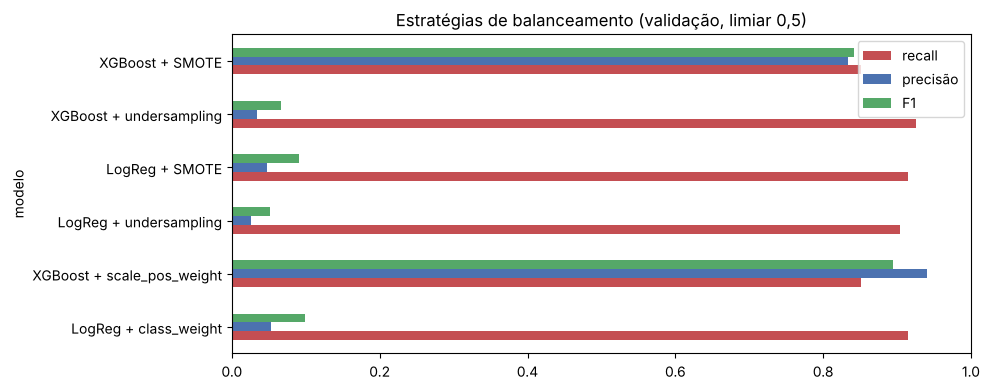

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
comparacao_bal[["recall", "precisão", "F1"]].plot.barh(ax=ax, color=["#C44E52", "#4C72B0", "#55A868"])
ax.set_xlim(0, 1); ax.set_title("Estratégias de balanceamento (validação, limiar 0,5)")
plt.tight_layout(); plt.savefig("imagens/balanceamento.png", dpi=110); plt.show()

**Leitura:**
- **Undersampling** dá o maior recall (XGBoost: 87 de 94 fraudes), mas descarta quase todas as transações normais do treino e o modelo passa a gerar **milhares de alarmes falsos**. A PR-AUC cai bastante.
- **SMOTE** (oversampling) na Regressão Logística fica praticamente igual ao peso das classes. No XGBoost, ele detecta as mesmas 80 fraudes, mas com 16 alarmes falsos, contra 5 do peso das classes.
- No XGBoost, o **peso das classes** (`scale_pos_weight`) entrega o melhor equilíbrio e a maior PR-AUC, sem descartar nem inventar dados.

Seguimos com o **XGBoost com peso das classes**, que também tem a melhor PR-AUC, e ajustamos seus hiperparâmetros.

## 5. Ajuste de hiperparâmetros com `GridSearchCV`

Validação cruzada estratificada (3 folds) usando **`average_precision` (PR-AUC)** como critério, e não a acurácia.

In [15]:
grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=peso, eval_metric="aucpr", tree_method="hist",
                  learning_rate=0.1, n_jobs=-1, random_state=SEED),
    param_grid={
        "n_estimators": [200, 400],
        "max_depth": [4, 6],
        "subsample": [0.8, 1.0],
    },
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    n_jobs=1,
)
inicio = time.time()
grid.fit(X_train_s, y_train)
print(f"Busca concluída em {time.time() - inicio:.0f}s")
print("Melhores parâmetros:", grid.best_params_)
print(f"PR-AUC média na validação cruzada: {grid.best_score_:.4f}")

pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
  .sort_values("rank_test_score")

Busca concluída em 67s
Melhores parâmetros: {'max_depth': 4, 'n_estimators': 400, 'subsample': 0.8}
PR-AUC média na validação cruzada: 0.8404


,params,mean_test_score,std_test_score,rank_test_score
2,"{'max_depth': 4, 'n_estimators': 400, 'subsamp...",0.8404,0.0622,1
4,"{'max_depth': 6, 'n_estimators': 200, 'subsamp...",0.8389,0.0636,2
6,"{'max_depth': 6, 'n_estimators': 400, 'subsamp...",0.8383,0.0623,3
3,"{'max_depth': 4, 'n_estimators': 400, 'subsamp...",0.8376,0.0673,4
0,"{'max_depth': 4, 'n_estimators': 200, 'subsamp...",0.8370,0.0607,5
1,"{'max_depth': 4, 'n_estimators': 200, 'subsamp...",0.8370,0.0692,6
7,"{'max_depth': 6, 'n_estimators': 400, 'subsamp...",0.8298,0.0699,7
5,"{'max_depth': 6, 'n_estimators': 200, 'subsamp...",0.8279,0.0717,8


In [16]:
xgb = grid.best_estimator_
probas["XGBoost ajustado"] = xgb.predict_proba(X_val_s)[:, 1]
pd.DataFrame([metricas("XGBoost ajustado", y_val, probas["XGBoost ajustado"])]).set_index("modelo")

,limiar,recall,precisão,F1,PR-AUC,ROC-AUC,fraudes detectadas,alarmes falsos
modelo,,,,,,,,
XGBoost ajustado,0.5000,0.8511,0.9302,0.8889,0.8864,0.9742,80/94,6


## 6. Ajuste do limiar de decisão

O limiar padrão de 0,5 não é obrigatório. Cada limiar gera um par diferente de recall e precisão.
Como **deixar passar uma fraude custa mais do que investigar um alarme falso**, o limiar é escolhido para **maximizar o F2** na validação: o F2 dá **o dobro de peso ao recall** em relação à precisão.

O ajuste é feito para os três modelos (Regressão Logística, Random Forest e XGBoost), como a Expert sugere.

In [17]:
def melhor_limiar(y_true, proba, beta=2):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    fb = (1 + beta**2) * prec[:-1] * rec[:-1] / np.clip(beta**2 * prec[:-1] + rec[:-1], 1e-12, None)
    i = np.nanargmax(fb)
    return thr[i]

candidatos = {
    "Regressão Logística": (modelos["LogReg + class_weight"], probas["LogReg + class_weight"]),
    "Random Forest": (modelos["Random Forest + class_weight"], probas["Random Forest + class_weight"]),
    "XGBoost": (xgb, probas["XGBoost ajustado"]),
}
limiares = {nome: melhor_limiar(y_val, p) for nome, (_, p) in candidatos.items()}
pd.Series(limiares, name="limiar escolhido (máx. F2 na validação)").to_frame()

,limiar escolhido (máx. F2 na validação)
Regressão Logística,0.9998
Random Forest,0.2464
XGBoost,0.4024


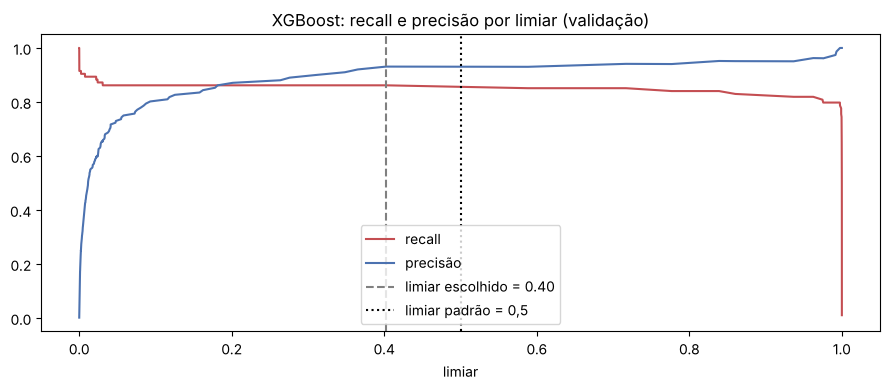

In [18]:
# Como recall e precisão variam com o limiar no XGBoost
prec, rec, thr = precision_recall_curve(y_val, probas["XGBoost ajustado"])
plt.figure(figsize=(9, 4))
plt.plot(thr, rec[:-1], label="recall", color="#C44E52")
plt.plot(thr, prec[:-1], label="precisão", color="#4C72B0")
plt.axvline(limiares["XGBoost"], ls="--", color="gray", label=f"limiar escolhido = {limiares['XGBoost']:.2f}")
plt.axvline(0.5, ls=":", color="black", label="limiar padrão = 0,5")
plt.xlabel("limiar"); plt.title("XGBoost: recall e precisão por limiar (validação)"); plt.legend()
plt.tight_layout(); plt.savefig("imagens/limiar.png", dpi=110); plt.show()

## 7. Avaliação final no conjunto de teste

Agora, e só agora, os modelos são avaliados no **teste**, que não participou de nenhuma escolha (nem de hiperparâmetros, nem de limiar).

In [19]:
final, probas_teste = [], {}
for nome, (modelo, _) in candidatos.items():
    p = modelo.predict_proba(X_test_s)[:, 1]
    probas_teste[nome] = p
    final.append(metricas(f"{nome} (limiar 0,5)", y_test, p, 0.5))
    final.append(metricas(f"{nome} (limiar ajustado)", y_test, p, limiares[nome]))

tabela_final = pd.DataFrame(final).set_index("modelo")
tabela_final.to_csv("resultados/comparacao_modelos_teste.csv")
tabela_final

,limiar,recall,precisão,F1,PR-AUC,ROC-AUC,fraudes detectadas,alarmes falsos
modelo,,,,,,,,
"Regressão Logística (limiar 0,5)",0.5000,0.8737,0.0496,0.0938,0.6796,0.9611,83/95,1591
Regressão Logística (limiar ajustado),0.9998,0.7684,0.7766,0.7725,0.6796,0.9611,73/95,21
"Random Forest (limiar 0,5)",0.5000,0.7053,0.9710,0.8171,0.8089,0.9387,67/95,2
Random Forest (limiar ajustado),0.2464,0.7579,0.9114,0.8276,0.8089,0.9387,72/95,7
"XGBoost (limiar 0,5)",0.5000,0.7684,0.9481,0.8488,0.8167,0.9739,73/95,4
XGBoost (limiar ajustado),0.4024,0.7789,0.9487,0.8555,0.8167,0.9739,74/95,4


In [20]:
print("XGBoost com limiar ajustado — relatório de classificação no teste\n")
pred_final = (probas_teste["XGBoost"] >= limiares["XGBoost"]).astype(int)
print(classification_report(y_test, pred_final, target_names=["Normal", "Fraude"], digits=4))

XGBoost com limiar ajustado — relatório de classificação no teste

              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
      Fraude     0.9487    0.7789    0.8555        95

    accuracy                         0.9996     56746
   macro avg     0.9742    0.8894    0.9276     56746
weighted avg     0.9995    0.9996    0.9995     56746



### Quanto custa pegar mais fraudes?

O limiar é uma decisão de negócio. A tabela mostra, no teste, o que acontece com o XGBoost ao baixar o limiar: cada fraude a mais detectada vem acompanhada de mais alarmes falsos.

In [21]:
pontos = [metricas("XGBoost", y_test, probas_teste["XGBoost"], l) for l in [0.9, 0.5, limiares["XGBoost"], 0.1, 0.02, 0.005]]
pd.DataFrame(pontos).drop(columns=["modelo", "PR-AUC", "ROC-AUC"]).set_index("limiar")

,recall,precisão,F1,fraudes detectadas,alarmes falsos
limiar,,,,,
0.9000,0.7474,0.9861,0.8503,71/95,1
0.5000,0.7684,0.9481,0.8488,73/95,4
0.4024,0.7789,0.9487,0.8555,74/95,4
0.1000,0.8105,0.8370,0.8235,77/95,15
0.0200,0.8105,0.5969,0.6875,77/95,52
0.0050,0.8211,0.3545,0.4952,78/95,142


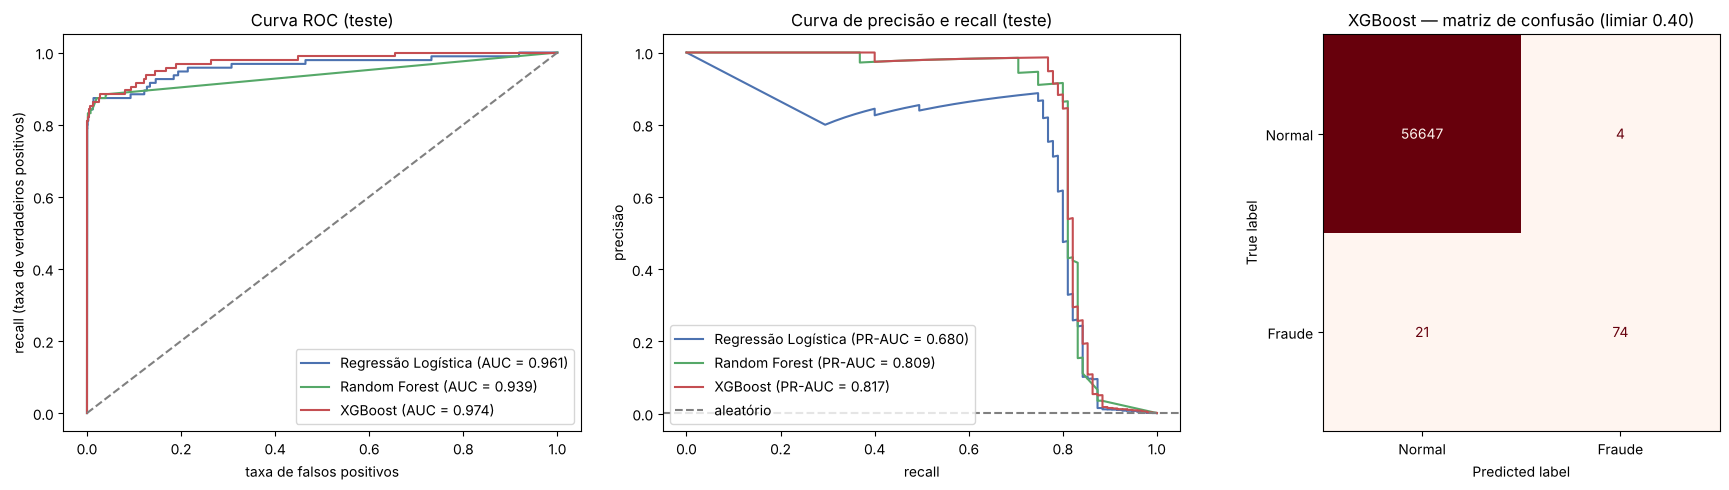

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cores = {"Regressão Logística": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52"}

for nome, p in probas_teste.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=cores[nome], label=f"{nome} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray")
axes[0].set_xlabel("taxa de falsos positivos"); axes[0].set_ylabel("recall (taxa de verdadeiros positivos)")
axes[0].set_title("Curva ROC (teste)"); axes[0].legend(loc="lower right")

for nome, p in probas_teste.items():
    prec_t, rec_t, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec_t, prec_t, color=cores[nome], label=f"{nome} (PR-AUC = {average_precision_score(y_test, p):.3f})")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label="aleatório")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precisão")
axes[1].set_title("Curva de precisão e recall (teste)"); axes[1].legend(loc="lower left")

ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Normal", "Fraude"],
                                        cmap="Reds", ax=axes[2], colorbar=False)
axes[2].set_title(f"XGBoost — matriz de confusão (limiar {limiares['XGBoost']:.2f})")

plt.tight_layout(); plt.savefig("imagens/curvas_teste.png", dpi=110); plt.show()

**Por que olhar a curva de precisão e recall e não só a ROC?** Com tão poucas fraudes, a curva ROC fica quase colada no canto superior esquerdo para todos os modelos (ROC-AUC acima de 0,93), porque a taxa de falsos positivos é dividida por um número enorme de transações normais. A curva de precisão e recall mostra a diferença real: a Regressão Logística perde muita precisão quando tenta aumentar o recall, enquanto os modelos de árvore mantêm a precisão alta por mais tempo.

## 8. Explicabilidade

### 8.1 Importância das variáveis (XGBoost)

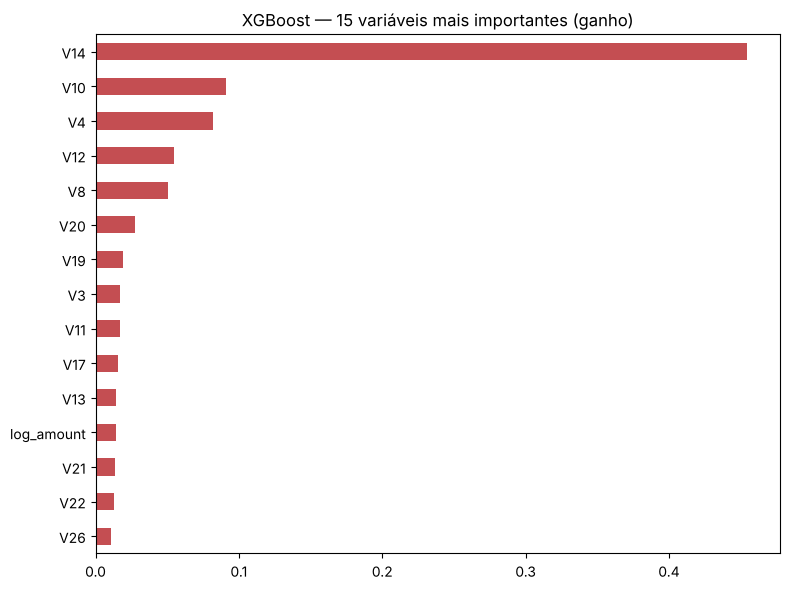

In [23]:
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 6))
imp.tail(15).plot.barh(color="#C44E52")
plt.title("XGBoost — 15 variáveis mais importantes (ganho)"); plt.tight_layout()
plt.savefig("imagens/importancia_variaveis.png", dpi=110); plt.show()

### 8.2 SHAP

A importância das variáveis diz **o que o modelo usa no geral**. O SHAP vai além: mostra **quanto cada variável empurrou cada previsão** para fraude ou para normal.

Para o gráfico global, usamos uma amostra do teste (todas as fraudes + 3.000 normais).

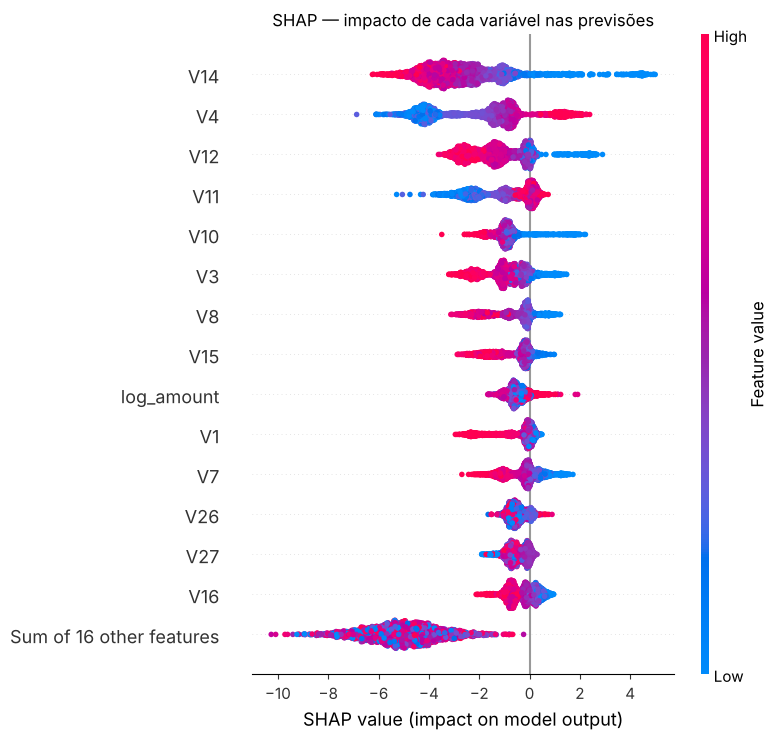

In [24]:
amostra = pd.concat([X_test_s[y_test == 1], X_test_s[y_test == 0].sample(3000, random_state=SEED)])
explainer = shap.TreeExplainer(xgb)
sv = explainer(amostra)

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP — impacto de cada variável nas previsões")
plt.tight_layout(); plt.savefig("imagens/shap_beeswarm.png", dpi=110, bbox_inches="tight"); plt.show()

**Como ler:** cada ponto é uma transação. Pontos à **direita** empurram a previsão para **fraude**; a cor indica se o valor da variável era alto (vermelho) ou baixo (azul). Por exemplo, valores **baixos** de `V14`, `V12`, `V10` e `V3` e valores **altos** de `V4` e `V11` aumentam a chance de fraude.

### 8.3 Por que **esta** transação foi marcada como fraude?

Pegamos uma fraude real do teste que o modelo detectou e vemos a contribuição de cada variável:

Transação 115676 | probabilidade de fraude prevista: 0.9997
Valor original: 76.94 | hora: 20h


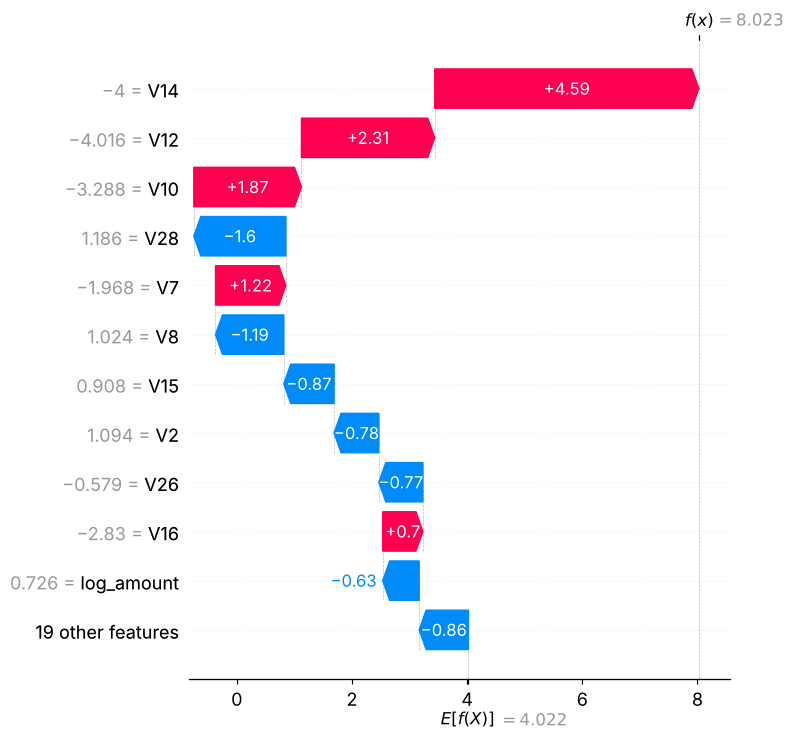

In [25]:
detectadas = X_test_s[(y_test == 1) & (pred_final == 1)]
idx = detectadas.index[0]
pos = amostra.index.get_loc(idx)
print(f"Transação {idx} | probabilidade de fraude prevista: {xgb.predict_proba(X_test_s.loc[[idx]])[0, 1]:.4f}")
print(f"Valor original: {df.loc[idx, 'Amount']:.2f} | hora: {int(df.loc[idx, 'hora'])}h")

shap.plots.waterfall(sv[pos], max_display=12, show=False)
plt.tight_layout(); plt.savefig("imagens/shap_waterfall.png", dpi=110, bbox_inches="tight"); plt.show()

**Leitura:** o gráfico começa no valor médio do modelo (o "chute" para uma transação qualquer, em escala log-odds) e soma a contribuição de cada variável até chegar na previsão final. As barras vermelhas empurram para fraude; as azuis, para normal. Isso permite **justificar cada alerta** para um analista de fraude.

### 8.4 E uma fraude que o modelo **não** pegou?

Fraudes não detectadas no teste: 21 de 95
Transação 239334 | probabilidade prevista: 0.0015


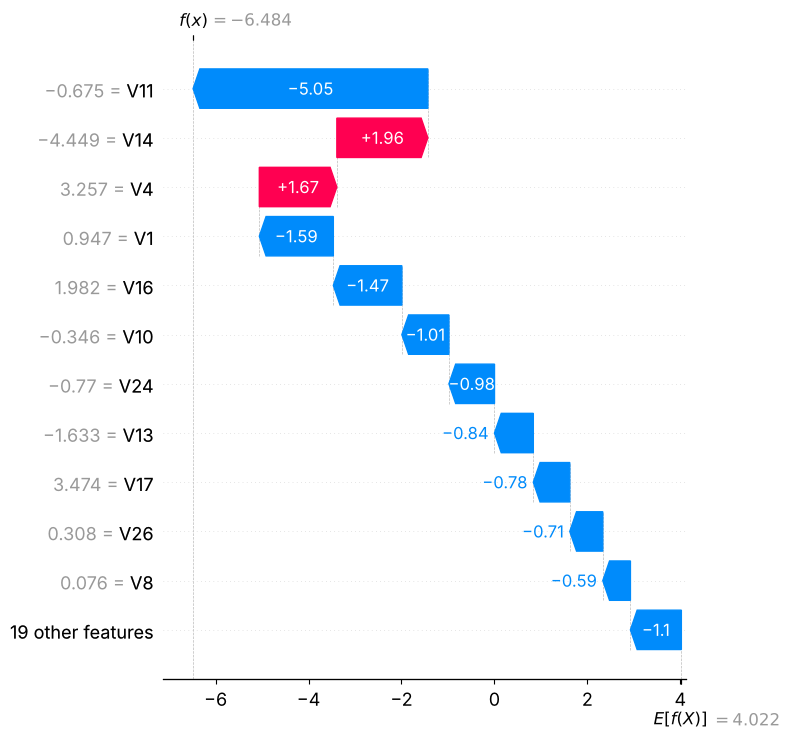

In [26]:
perdidas = X_test_s[(y_test == 1) & (pred_final == 0)]
print(f"Fraudes não detectadas no teste: {len(perdidas)} de {int(y_test.sum())}")
if len(perdidas) > 0:
    idx_p = perdidas.index[0]
    pos_p = amostra.index.get_loc(idx_p)
    print(f"Transação {idx_p} | probabilidade prevista: {xgb.predict_proba(X_test_s.loc[[idx_p]])[0, 1]:.4f}")
    shap.plots.waterfall(sv[pos_p], max_display=12, show=False)
    plt.tight_layout(); plt.show()

A tabela abaixo compara as variáveis mais importantes (valores padronizados, mediana) entre transações normais, fraudes detectadas e fraudes que escaparam:

In [27]:
top = ["V14", "V4", "V12", "V11", "V10", "V3"]
grupos = pd.concat({
    "normais": X_test_s.loc[y_test == 0, top].median(),
    "fraudes detectadas": X_test_s.loc[(y_test == 1) & (pred_final == 1), top].median(),
    "fraudes que escaparam": X_test_s.loc[(y_test == 1) & (pred_final == 0), top].median(),
}, axis=1).T
grupos

,V14,V4,V12,V11,V10,V3
normais,0.0609,-0.0168,0.1464,-0.0362,-0.0831,0.1228
fraudes detectadas,-7.3218,3.1658,-6.1844,4.0097,-4.6664,-3.8376
fraudes que escaparam,-0.9739,1.0545,-0.2851,0.0044,-0.2626,-0.2349


As fraudes que escaparam têm valores dessas variáveis **bem mais próximos dos de transações normais** do que as fraudes detectadas. Ou seja, elas "se disfarçam" de transação comum e o modelo não tem sinal suficiente para separá-las. Isso indica que **novas variáveis** (por exemplo, comportamento do mesmo cartão ao longo do tempo) seriam o caminho para melhorar, mas essa informação não existe nesta base anonimizada.

## 9. Conclusões

In [28]:
resumo_final = tabela_final.loc[[f"{n} (limiar ajustado)" for n in candidatos],
                                ["limiar", "recall", "precisão", "F1", "PR-AUC", "fraudes detectadas", "alarmes falsos"]]
resumo_final

,limiar,recall,precisão,F1,PR-AUC,fraudes detectadas,alarmes falsos
modelo,,,,,,,
Regressão Logística (limiar ajustado),0.9998,0.7684,0.7766,0.7725,0.6796,73/95,21
Random Forest (limiar ajustado),0.2464,0.7579,0.9114,0.8276,0.8089,72/95,7
XGBoost (limiar ajustado),0.4024,0.7789,0.9487,0.8555,0.8167,74/95,4


- **A acurácia não serve** para este problema: um modelo inútil teria mais de 99,8%.
- A **Regressão Logística com peso das classes** tem recall alto, mas gera alarmes falsos demais para uso prático.
- **Undersampling** aumenta o recall, mas derruba a precisão; **SMOTE** fica no meio; o **peso das classes no XGBoost** deu o melhor equilíbrio.
- O **XGBoost ajustado com `GridSearchCV`** (critério PR-AUC) e com **limiar escolhido na validação pelo F2** foi o melhor modelo no teste, com a maior PR-AUC e o melhor equilíbrio entre recall e precisão.
- O **SHAP** mostra que `V14`, `V4`, `V12`, `V11` e `V10` são as variáveis que mais pesam, e permite explicar cada alerta individualmente.
- As fraudes que escapam têm perfil parecido com o de transações normais; para pegá-las seria preciso baixar muito o limiar (com muito mais alarmes falsos) ou ter novas variáveis.

**Próximos passos:** testar custos reais (valor da fraude × custo de investigar um alerta) para escolher o limiar, e incluir variáveis de comportamento do cliente se houver um identificador de cartão.